# Sprint 8 — Projeto de Análise de Negócios

## Introdução

A Y.Afisha deseja otimizar suas despesas com marketing.

O objetivo deste projeto é analisar o comportamento dos usuários, as vendas e os investimentos em marketing, identificando quais origens de anúncios trazem os melhores resultados para a empresa.

A análise será dividida em três áreas:

- Produto: atividade, sessões e retenção dos usuários;
- Vendas: conversão, pedidos, receita média e LTV;
- Marketing: despesas, CAC e retorno sobre o investimento.

Ao final, serão apresentadas recomendações sobre quais origens de anúncios devem receber mais investimentos.

### 1.1 Importação das bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1.2 Carregamento dos dados

In [2]:
# Carregando os dados de visitas ao site
visits = pd.read_csv('/datasets/visits_log_us.csv')

# Carregando os dados dos pedidos
orders = pd.read_csv('/datasets/orders_log_us.csv')

# Carregando os dados das despesas de marketing
costs = pd.read_csv('/datasets/costs_us.csv')

### 1.3 Visualização inicial dos dados

In [3]:
# Visualizando as primeiras linhas da tabela de visitas
print('VISITAS')
display(visits.head())

# Visualizando as primeiras linhas da tabela de pedidos
print('PEDIDOS')
display(orders.head())

# Visualizando as primeiras linhas da tabela de despesas
print('DESPESAS')
display(costs.head())

VISITAS


,Device,End Ts,Source Id,Start Ts,Uid
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168


PEDIDOS


,Buy Ts,Revenue,Uid
0,2017-06-01 00:10:00,17.00,10329302124590727494
1,2017-06-01 00:25:00,0.55,11627257723692907447
2,2017-06-01 00:27:00,0.37,17903680561304213844
3,2017-06-01 00:29:00,0.55,16109239769442553005
4,2017-06-01 07:58:00,0.37,14200605875248379450


DESPESAS


,source_id,dt,costs
0,1,2017-06-01,75.20
1,1,2017-06-02,62.25
2,1,2017-06-03,36.53
3,1,2017-06-04,55.00
4,1,2017-06-05,57.08


### 1.4 Informações gerais das tabelas

In [4]:
# Verificando as colunas, os tipos de dados e a quantidade de valores preenchidos

print('Formato de visits:', visits.shape)
print('Formato de orders:', orders.shape)
print('Formato de costs:', costs.shape)

Formato de visits: (359400, 5)
Formato de orders: (50415, 3)
Formato de costs: (2542, 3)


### 1.5 Padronização dos nomes das colunas

Os nomes serão transformados em letras minúsculas e os espaços serão substituídos por _. Isso facilitará o uso das colunas durante a análise.

In [5]:
# Padronizando os nomes das colunas da tabela de visitas
visits.columns = (
    visits.columns
    .str.lower()
    .str.replace(' ', '_')
)

# Padronizando os nomes das colunas da tabela de pedidos
orders.columns = (
    orders.columns
    .str.lower()
    .str.replace(' ', '_')
)

# Padronizando os nomes das colunas da tabela de despesas
costs.columns = (
    costs.columns
    .str.lower()
    .str.replace(' ', '_')
)

# Conferindo os novos nomes das colunas
print('Colunas de visits:', visits.columns.tolist())
print('Colunas de orders:', orders.columns.tolist())
print('Colunas de costs:', costs.columns.tolist())

Colunas de visits: ['device', 'end_ts', 'source_id', 'start_ts', 'uid']
Colunas de orders: ['buy_ts', 'revenue', 'uid']
Colunas de costs: ['source_id', 'dt', 'costs']


### 1.6 Conversão das colunas de data

In [6]:
# Convertendo as datas de início e fim das sessões
visits['start_ts'] = pd.to_datetime(visits['start_ts'])
visits['end_ts'] = pd.to_datetime(visits['end_ts'])

# Convertendo a data e hora dos pedidos
orders['buy_ts'] = pd.to_datetime(orders['buy_ts'])

# Convertendo a data das despesas
costs['dt'] = pd.to_datetime(costs['dt'])

### 1.7 Verificação de valores ausentes

In [7]:
# Verificando valores ausentes em cada tabela

print('VALORES AUSENTES EM VISITS')
print(visits.isna().sum())

print('\nVALORES AUSENTES EM ORDERS')
print(orders.isna().sum())

print('\nVALORES AUSENTES EM COSTS')
print(costs.isna().sum())

VALORES AUSENTES EM VISITS
device       0
end_ts       0
source_id    0
start_ts     0
uid          0
dtype: int64

VALORES AUSENTES EM ORDERS
buy_ts     0
revenue    0
uid        0
dtype: int64

VALORES AUSENTES EM COSTS
source_id    0
dt           0
costs        0
dtype: int64


### 1.8 Verificação de duplicados

In [8]:
# Verificando a quantidade de linhas totalmente duplicadas

print('Duplicados em visits:', visits.duplicated().sum())
print('Duplicados em orders:', orders.duplicated().sum())
print('Duplicados em costs:', costs.duplicated().sum())

Duplicados em visits: 0
Duplicados em orders: 0
Duplicados em costs: 0


### 1.9 Verificação final dos tipos de dados

In [9]:
# Conferindo os tipos após as conversões

print('TIPOS DE DADOS EM VISITS')
print(visits.dtypes)

print('\nTIPOS DE DADOS EM ORDERS')
print(orders.dtypes)

print('\nTIPOS DE DADOS EM COSTS')
print(costs.dtypes)

TIPOS DE DADOS EM VISITS
device               object
end_ts       datetime64[ns]
source_id             int64
start_ts     datetime64[ns]
uid                  uint64
dtype: object

TIPOS DE DADOS EM ORDERS
buy_ts     datetime64[ns]
revenue           float64
uid                uint64
dtype: object

TIPOS DE DADOS EM COSTS
source_id             int64
dt           datetime64[ns]
costs               float64
dtype: object


### Conclusão da preparação dos dados

Os três conjuntos de dados foram carregados corretamente.

Os nomes das colunas foram padronizados para letras minúsculas e os espaços foram substituídos por sublinhados.

As colunas relacionadas a datas foram convertidas para o tipo datetime, permitindo a criação de análises diárias, semanais e mensais.

Também foram verificados valores ausentes e registros duplicados. Após essa preparação, os dados estão prontos para a análise das métricas de produto, vendas e marketing.

# Passo 2 — Relatórios e cálculo das métricas

Nesta etapa serão analisadas as métricas relacionadas ao Produto, Vendas e Marketing.

## 2.1 Produto

Nesta seção serão analisadas as métricas relacionadas ao uso da plataforma pelos usuários.

Serão respondidas as seguintes perguntas:

- Quantas pessoas usam o produto por dia, semana e mês?
- Quantas sessões ocorrem por dia?
- Qual é a duração de cada sessão?
- Com que frequência os usuários retornam?

### 2.1.1 Usuários ativos por dia, semana e mês? (DAU, WAU e MAU)
##### Objetivo

Primeiramente, vamos calcular a quantidade de usuários ativos por dia, semana e mês. Essas métricas permitem acompanhar o comportamento dos usuários ao longo do tempo e identificar possíveis tendências de crescimento ou redução da atividade na plataforma.

In [10]:
# Criando colunas auxiliares para as análises

visits['session_date'] = visits['start_ts'].dt.date

visits['session_week'] = (
    visits['start_ts']
    .dt.to_period('W')
    .apply(lambda x: x.start_time)
)

visits['session_month'] = (
    visits['start_ts']
    .dt.to_period('M')
    .dt.to_timestamp()
)

#### Calculando o DAU

In [11]:
# Quantidade de usuários ativos por dia

dau = (
    visits.groupby('session_date')
    .agg({'uid': 'nunique'})
    .reset_index()
)

dau.columns = ['session_date', 'dau']

display(dau.head())

,session_date,dau
0,2017-06-01,605
1,2017-06-02,608
2,2017-06-03,445
3,2017-06-04,476
4,2017-06-05,820


#### Calculando o WAU

In [12]:
# Quantidade de usuários ativos por semana

wau = (
    visits.groupby('session_week')
    .agg({'uid': 'nunique'})
    .reset_index()
)

wau.columns = ['session_week', 'wau']

display(wau.head())

,session_week,wau
0,2017-05-29,2021
1,2017-06-05,4129
2,2017-06-12,2812
3,2017-06-19,2878
4,2017-06-26,3064


#### Calculando o MAU

In [13]:
# Quantidade de usuários ativos por mês

mau = (
    visits.groupby('session_month')
    .agg({'uid': 'nunique'})
    .reset_index()
)

mau.columns = ['session_month', 'mau']

display(mau.head())

,session_month,mau
0,2017-06-01,13259
1,2017-07-01,14183
2,2017-08-01,11631
3,2017-09-01,18975
4,2017-10-01,29692


#### Média das métricas

In [14]:
# Calculando as médias

print('DAU médio:', round(dau['dau'].mean()))

print('WAU médio:', round(wau['wau'].mean()))

print('MAU médio:', round(mau['mau'].mean()))

DAU médio: 908
WAU médio: 5716
MAU médio: 23228


#### Evolução do DAU

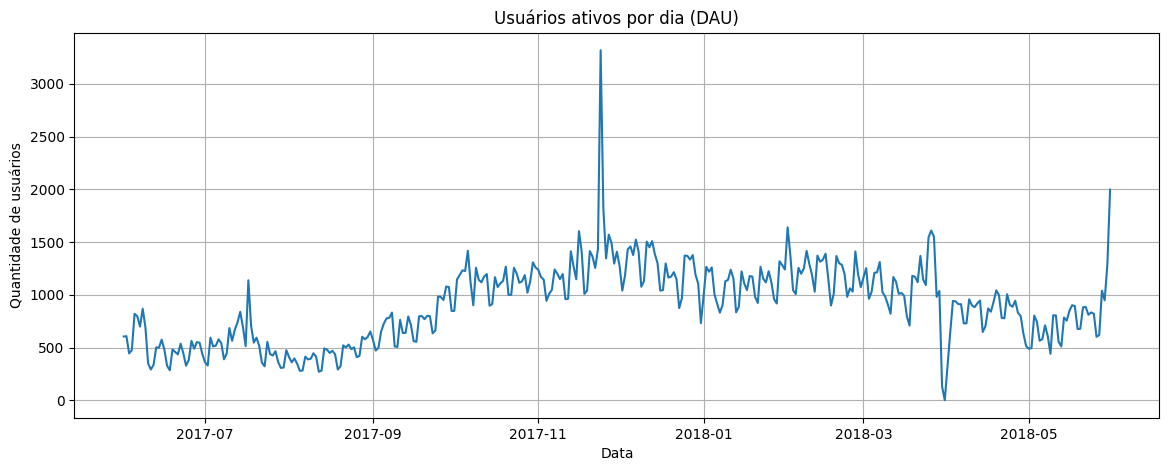

In [15]:
plt.figure(figsize=(14,5))

plt.plot(dau['session_date'], dau['dau'])

plt.title('Usuários ativos por dia (DAU)')
plt.xlabel('Data')
plt.ylabel('Quantidade de usuários')

plt.grid()

plt.show()

#### Evolução do WAU

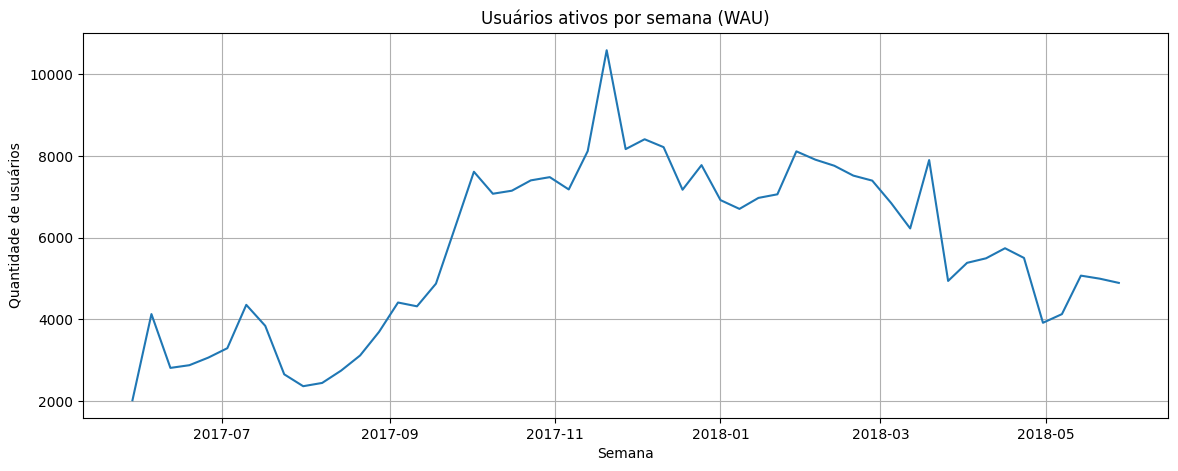

In [16]:
plt.figure(figsize=(14,5))

plt.plot(wau['session_week'], wau['wau'])

plt.title('Usuários ativos por semana (WAU)')
plt.xlabel('Semana')
plt.ylabel('Quantidade de usuários')

plt.grid()

plt.show()

#### Evolução do MAU

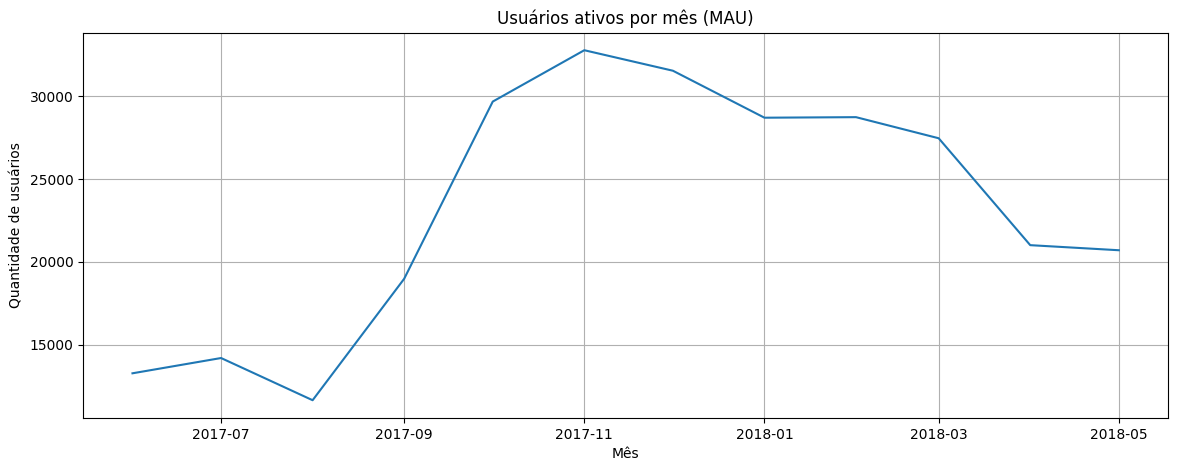

In [17]:
plt.figure(figsize=(14,5))

plt.plot(mau['session_month'], mau['mau'])

plt.title('Usuários ativos por mês (MAU)')
plt.xlabel('Mês')
plt.ylabel('Quantidade de usuários')

plt.grid()

plt.show()


### Conclusão

Em média, a plataforma teve aproximadamente 908 usuários ativos por dia, 5.716 por semana e 23.228 por mês.

Os gráficos mostram que a atividade dos usuários cresceu até o final de 2017 e diminuiu nos meses seguintes. Essas métricas serão úteis para comparar os resultados das próximas análises.
.

### 2.1.2 Quantas sessões ocorrem por dia?

#### Objetivo

Nesta etapa será calculada a quantidade de sessões realizadas por dia.

Diferente do DAU, em que cada usuário é contado apenas uma vez por dia, aqui serão contabilizadas todas as sessões realizadas, pois um mesmo usuário pode acessar a plataforma várias vezes no mesmo dia.

In [18]:
# Calculando a quantidade de sessões por dia

sessions_per_day = (
    visits.groupby('session_date')
    .agg({'uid': 'count'})
    .reset_index()
)

# Renomeando as colunas
sessions_per_day.columns = ['session_date', 'sessions']

# Exibindo as primeiras linhas
display(sessions_per_day.head())

,session_date,sessions
0,2017-06-01,664
1,2017-06-02,658
2,2017-06-03,477
3,2017-06-04,510
4,2017-06-05,893


In [19]:
# Calculando a média de sessões por dia

print('Média de sessões por dia:',
      round(sessions_per_day['sessions'].mean()))

Média de sessões por dia: 987


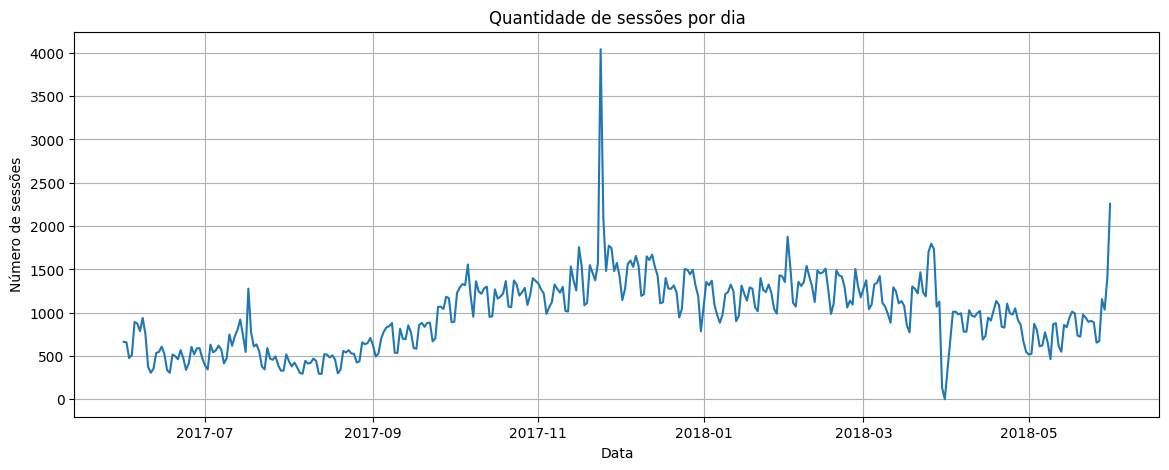

In [20]:
plt.figure(figsize=(14,5))

plt.plot(
    sessions_per_day['session_date'],
    sessions_per_day['sessions']
)

plt.title('Quantidade de sessões por dia')
plt.xlabel('Data')
plt.ylabel('Número de sessões')

plt.grid()

plt.show()

### Conclusão

Foi calculada a quantidade de sessões realizadas por dia.

O gráfico mostra como o número de sessões variou ao longo do período analisado, permitindo identificar dias com maior ou menor atividade dos usuários.

Essa métrica complementa o DAU, pois considera todas as sessões realizadas, inclusive quando um mesmo usuário acessa a plataforma mais de uma vez no mesmo dia.

### 2.1.3 Qual é a duração das sessões?

### Objetivo

Nesta etapa será calculada a duração das sessões dos usuários.

Essa análise permite entender quanto tempo, em média, os usuários permanecem utilizando a plataforma durante cada acesso.

In [21]:
# Calculando a duração das sessões em segundos

visits['session_duration_sec'] = (
    visits['end_ts'] - visits['start_ts']
).dt.seconds

# Exibindo as primeiras linhas
display(visits[['start_ts', 'end_ts', 'session_duration_sec']].head())

,start_ts,end_ts,session_duration_sec
0,2017-12-20 17:20:00,2017-12-20 17:38:00,1080
1,2018-02-19 16:53:00,2018-02-19 17:21:00,1680
2,2017-07-01 01:54:00,2017-07-01 01:54:00,0
3,2018-05-20 10:59:00,2018-05-20 11:23:00,1440
4,2017-12-27 14:06:00,2017-12-27 14:06:00,0


In [22]:
# Exibindo estatísticas da duração das sessões

display(visits['session_duration_sec'].describe())

count    359400.000000
mean        643.506489
std        1016.334786
min           0.000000
25%         120.000000
50%         300.000000
75%         840.000000
max       84480.000000
Name: session_duration_sec, dtype: float64

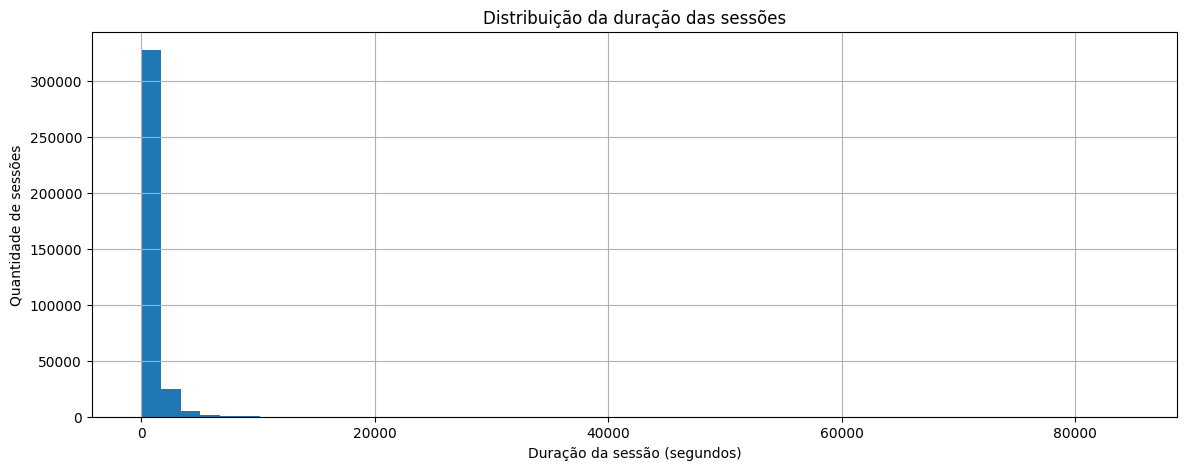

In [23]:
plt.figure(figsize=(14,5))

plt.hist(visits['session_duration_sec'], bins=50)

plt.title('Distribuição da duração das sessões')
plt.xlabel('Duração da sessão (segundos)')
plt.ylabel('Quantidade de sessões')

plt.grid()

plt.show()

In [24]:
print('Duração média da sessão:',
      round(visits['session_duration_sec'].mean(), 2),
      'segundos')

Duração média da sessão: 643.51 segundos


### Conclusão

Foi calculada a duração das sessões dos usuários.

A duração média das sessões foi de aproximadamente 644 segundos. O histograma mostra que a maior parte das sessões possui duração menor, enquanto poucas sessões permanecem abertas por um período muito maior.

Essas informações ajudam a entender o comportamento dos usuários durante o uso da plataforma.

### 2.1.4 Com que frequência os usuários voltam?

#### Objetivo

Nesta etapa será analisada a frequência com que os usuários retornam à plataforma.

Para isso, será calculada a taxa de retenção por coortes mensais, permitindo acompanhar o percentual de usuários que continuam utilizando o serviço ao longo do tempo.

In [25]:
# Criando o mês da primeira visita de cada usuário

first_visit = (
    visits.groupby('uid')
    .agg({'start_ts':'min'})
    .reset_index()
)

first_visit['first_session_month'] = (
    first_visit['start_ts']
    .dt.to_period('M')
    .dt.to_timestamp()
)

display(first_visit.head())

,uid,start_ts,first_session_month
0,11863502262781,2018-03-01 17:27:00,2018-03-01
1,49537067089222,2018-02-06 15:55:00,2018-02-01
2,297729379853735,2017-06-07 18:47:00,2017-06-01
3,313578113262317,2017-09-18 22:49:00,2017-09-01
4,325320750514679,2017-09-30 14:29:00,2017-09-01


In [26]:
# Adicionando o mês da primeira visita ao DataFrame principal

visits = visits.merge(
    first_visit[['uid', 'first_session_month']],
    on='uid'
)

display(visits.head())

,device,end_ts,source_id,start_ts,uid,session_date,session_week,session_month,session_duration_sec,first_session_month
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062,2017-12-20,2017-12-18,2017-12-01,1080,2017-12-01
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740,2018-02-19,2018-02-19,2018-02-01,1680,2018-02-01
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527,2017-07-01,2017-06-26,2017-07-01,0,2017-07-01
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214,2018-05-20,2018-05-14,2018-05-01,1440,2018-03-01
4,desktop,2018-03-09 20:33:00,4,2018-03-09 20:05:00,16174680259334210214,2018-03-09,2018-03-05,2018-03-01,1680,2018-03-01


In [27]:
# Calculando a idade da coorte em meses

visits['cohort_age'] = (
    (visits['session_month'].dt.year - visits['first_session_month'].dt.year) * 12
    + (visits['session_month'].dt.month - visits['first_session_month'].dt.month)
)

display(
    visits[
        ['uid', 'first_session_month', 'session_month', 'cohort_age']
    ].head()
)

,uid,first_session_month,session_month,cohort_age
0,16879256277535980062,2017-12-01,2017-12-01,0
1,104060357244891740,2018-02-01,2018-02-01,0
2,7459035603376831527,2017-07-01,2017-07-01,0
3,16174680259334210214,2018-03-01,2018-05-01,2
4,16174680259334210214,2018-03-01,2018-03-01,0


In [28]:
# Calculando o número de usuários por coorte

cohorts = (
    visits.groupby(['first_session_month', 'cohort_age'])
    .agg({'uid':'nunique'})
    .reset_index()
)

In [29]:
# Calculando o tamanho inicial de cada coorte

cohort_sizes = (
    cohorts[cohorts['cohort_age'] == 0]
    [['first_session_month', 'uid']]
)

cohort_sizes.columns = [
    'first_session_month',
    'n_users'
]

display(cohort_sizes.head())

,first_session_month,n_users
0,2017-06-01,13259
12,2017-07-01,13140
23,2017-08-01,10181
33,2017-09-01,16704
42,2017-10-01,25977


In [30]:
# Calculando a taxa de retenção

retention = cohorts.merge(
    cohort_sizes,
    on='first_session_month'
)

retention['retention_rate'] = (
    retention['uid'] /
    retention['n_users']
)

display(retention.head())

,first_session_month,cohort_age,uid,n_users,retention_rate
0,2017-06-01,0,13259,13259,1.000000
1,2017-06-01,1,1043,13259,0.078664
2,2017-06-01,2,713,13259,0.053775
3,2017-06-01,3,814,13259,0.061392
4,2017-06-01,4,909,13259,0.068557


In [31]:
# Criando a tabela dinâmica da retenção

retention_pivot = retention.pivot_table(
    index='first_session_month',
    columns='cohort_age',
    values='retention_rate'
)

display(retention_pivot)

cohort_age,0,1,2,3,4,5,6,7,8,9,10,11
first_session_month,,,,,,,,,,,,
2017-06-01,1.0,0.078664,0.053775,0.061392,0.068557,0.071423,0.061015,0.057772,0.052342,0.050833,0.040652,0.044951
2017-07-01,1.0,0.056088,0.051294,0.056164,0.058219,0.048174,0.045358,0.045738,0.038813,0.028615,0.027473,NaN
2017-08-01,1.0,0.076908,0.062862,0.062764,0.050093,0.044004,0.036342,0.039485,0.027895,0.026029,NaN,NaN
2017-09-01,1.0,0.085489,0.069205,0.050706,0.039392,0.037835,0.035860,0.024186,0.022809,NaN,NaN,NaN
2017-10-01,1.0,0.078608,0.052239,0.038958,0.034261,0.032221,0.021365,0.020364,NaN,NaN,NaN,NaN
2017-11-01,1.0,0.078281,0.044113,0.038682,0.033727,0.023415,0.021800,NaN,NaN,NaN,NaN,NaN
2017-12-01,1.0,0.055802,0.037993,0.031107,0.020263,0.019036,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01,1.0,0.059715,0.039339,0.024973,0.020244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-01,1.0,0.057080,0.025454,0.020093,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


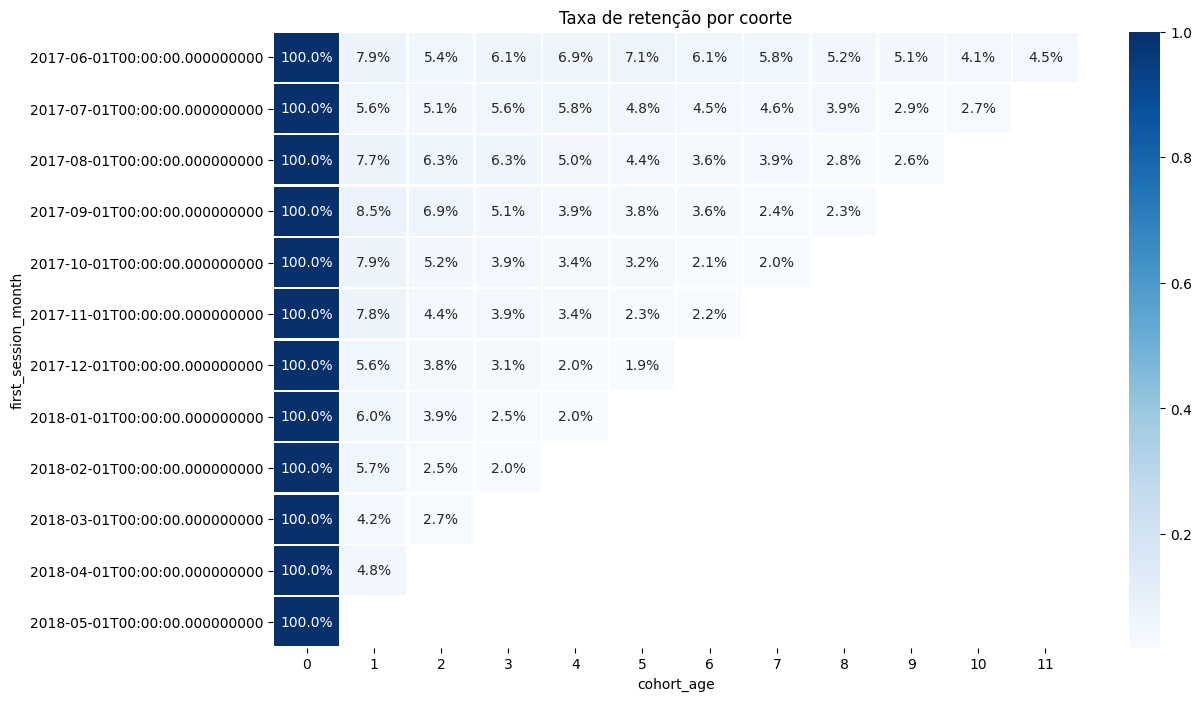

In [32]:
plt.figure(figsize=(13,8))

sns.heatmap(
    retention_pivot,
    annot=True,
    fmt='.1%',
    cmap='Blues',
    linewidths=1,
    linecolor='white'
)

plt.title('Taxa de retenção por coorte')

plt.show()

### Conclusão

Foi calculada a taxa de retenção dos usuários utilizando coortes mensais.

O mapa de calor mostra que todas as coortes iniciam com 100% de retenção no primeiro mês, como esperado. Nos meses seguintes ocorre uma redução significativa no percentual de usuários ativos, indicando que muitos deixam de utilizar a plataforma após o primeiro acesso.

Apesar dessa queda inicial, observa-se que uma pequena parcela dos usuários continua ativa nos meses seguintes, mantendo uma retenção entre aproximadamente 2% e 7%.

## 2.2 Vendas

Nesta seção serão analisadas as métricas relacionadas às compras realizadas pelos usuários.

Serão respondidas as seguintes perguntas:

- Quando as pessoas começam a comprar?
- Quantos pedidos os clientes fazem durante um determinado período?
- Qual é o volume médio de uma compra?
- Quanto dinheiro os clientes trazem para a empresa (LTV)?

### 2.2.1 Quando as pessoas começam a comprar?

#### Objetivo

Nesta etapa será analisado quanto tempo os usuários levam para realizar a primeira compra após a primeira visita ao site.

Essa análise permite entender a velocidade com que os visitantes se tornam clientes.

In [33]:
# Calculando a data da primeira compra de cada usuário

first_order = (
    orders.groupby('uid')
    .agg({'buy_ts': 'min'})
    .reset_index()
)

first_order.columns = ['uid', 'first_order_ts']

display(first_order.head())

,uid,first_order_ts
0,313578113262317,2018-01-03 21:51:00
1,1575281904278712,2017-06-03 10:13:00
2,2429014661409475,2017-10-11 18:33:00
3,2464366381792757,2018-01-28 15:54:00
4,2551852515556206,2017-11-24 10:14:00


In [34]:
# Unindo as informações da primeira visita e da primeira compra

conversion = first_visit.merge(
    first_order,
    on='uid'
)

display(conversion.head())

,uid,start_ts,first_session_month,first_order_ts
0,313578113262317,2017-09-18 22:49:00,2017-09-01,2018-01-03 21:51:00
1,1575281904278712,2017-06-03 10:13:00,2017-06-01,2017-06-03 10:13:00
2,2429014661409475,2017-10-11 17:14:00,2017-10-01,2017-10-11 18:33:00
3,2464366381792757,2018-01-27 20:10:00,2018-01-01,2018-01-28 15:54:00
4,2551852515556206,2017-11-24 10:14:00,2017-11-01,2017-11-24 10:14:00


In [35]:
# Calculando quantos dias o usuário levou para realizar a primeira compra

conversion['days_to_first_order'] = (
    conversion['first_order_ts']
    - conversion['start_ts']
).dt.days

display(conversion.head())

,uid,start_ts,first_session_month,first_order_ts,days_to_first_order
0,313578113262317,2017-09-18 22:49:00,2017-09-01,2018-01-03 21:51:00,106
1,1575281904278712,2017-06-03 10:13:00,2017-06-01,2017-06-03 10:13:00,0
2,2429014661409475,2017-10-11 17:14:00,2017-10-01,2017-10-11 18:33:00,0
3,2464366381792757,2018-01-27 20:10:00,2018-01-01,2018-01-28 15:54:00,0
4,2551852515556206,2017-11-24 10:14:00,2017-11-01,2017-11-24 10:14:00,0


In [36]:
# Exibindo estatísticas do tempo até a primeira compra

display(conversion['days_to_first_order'].describe())

count    36523.000000
mean        16.729869
std         46.959088
min          0.000000
25%          0.000000
50%          0.000000
75%          2.000000
max        363.000000
Name: days_to_first_order, dtype: float64

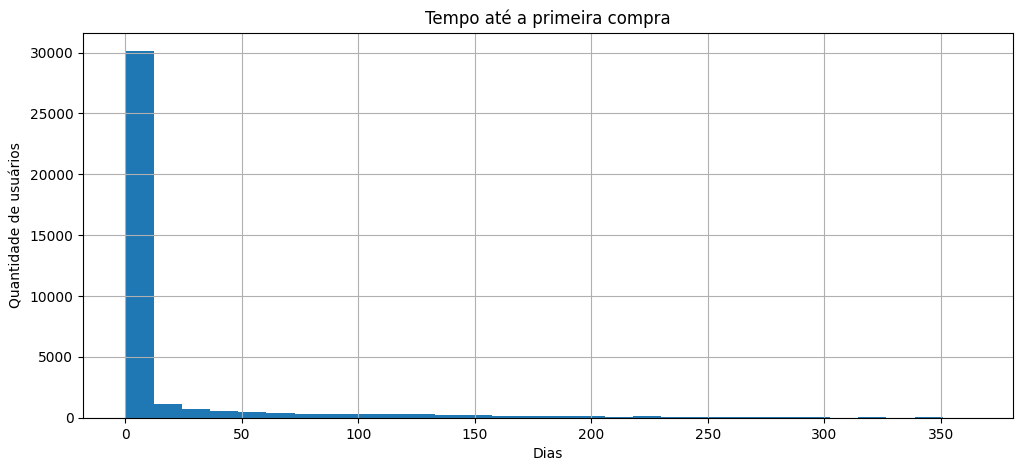

In [37]:
plt.figure(figsize=(12,5))

plt.hist(conversion['days_to_first_order'], bins=30)

plt.title('Tempo até a primeira compra')
plt.xlabel('Dias')
plt.ylabel('Quantidade de usuários')

plt.grid()

plt.show()

In [38]:
print(
    'Tempo médio até a primeira compra:',
    round(conversion['days_to_first_order'].mean(),2),
    'dias'
)

Tempo médio até a primeira compra: 16.73 dias


### Conclusão

Foi analisado o tempo que os usuários levam para realizar a primeira compra após a primeira visita ao site.

Os resultados mostram que muitos usuários efetuam a primeira compra no mesmo dia em que acessam a plataforma, como pode ser observado pela mediana igual a 0 dia e pelo histograma concentrado nos primeiros dias.

Apesar de o tempo médio até a primeira compra ser de aproximadamente 16,73 dias, esse valor é influenciado por alguns usuários que demoraram muito mais tempo para realizar a primeira compra.

Esses resultados indicam que uma parte significativa dos clientes converte rapidamente, enquanto uma parcela menor demora mais tempo para concluir a primeira compra.

### 2.2.2 Quantos pedidos os clientes fazem durante um determinado período?

#### Objetivo

Nesta etapa será analisada a quantidade de pedidos realizados pelos clientes ao longo do tempo.

Essa análise permite entender a frequência de compras dos usuários e identificar como o número de pedidos evolui durante o período analisado.

In [39]:
# Criando uma coluna com o mês da compra

orders['order_month'] = (
    orders['buy_ts']
    .dt.to_period('M')
    .dt.to_timestamp()
)

display(orders.head())

,buy_ts,revenue,uid,order_month
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017-06-01
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017-06-01
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017-06-01
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017-06-01
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017-06-01


In [40]:
# Calculando a quantidade de pedidos realizados em cada mês

orders_per_month = (
    orders.groupby('order_month')
    .agg({'uid':'count'})
    .reset_index()
)

orders_per_month.columns = ['order_month', 'n_orders']

display(orders_per_month)

,order_month,n_orders
0,2017-06-01,2354
1,2017-07-01,2363
2,2017-08-01,1807
3,2017-09-01,3387
4,2017-10-01,5679
5,2017-11-01,5659
6,2017-12-01,6218
7,2018-01-01,4721
8,2018-02-01,5281
9,2018-03-01,5326


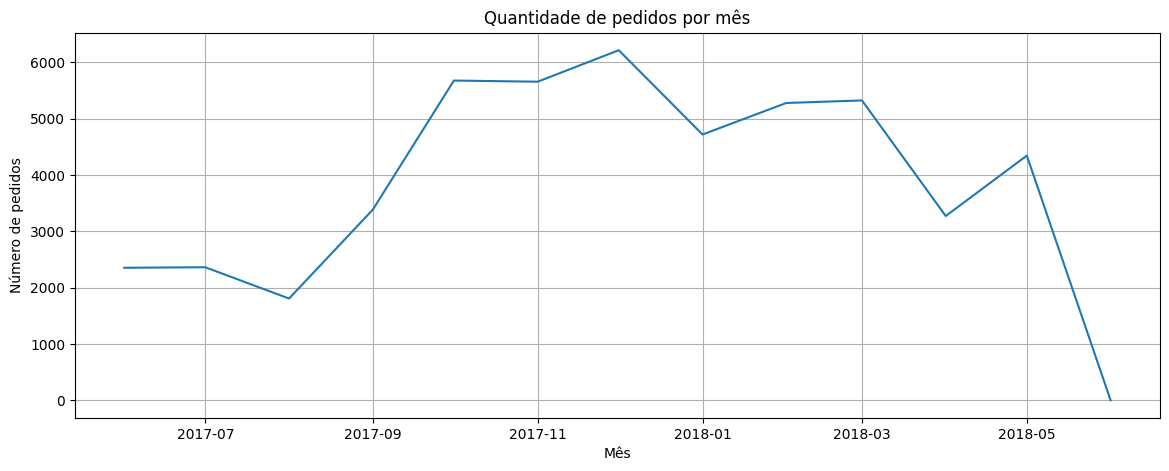

In [41]:
plt.figure(figsize=(14,5))

plt.plot(
    orders_per_month['order_month'],
    orders_per_month['n_orders']
)

plt.title('Quantidade de pedidos por mês')
plt.xlabel('Mês')
plt.ylabel('Número de pedidos')

plt.grid()

plt.show()

In [42]:
print(
    'Média de pedidos por mês:',
    round(orders_per_month['n_orders'].mean())
)

Média de pedidos por mês: 3878


### Conclusão

Foi analisada a quantidade de pedidos realizados pelos clientes ao longo do período.

O gráfico mostra que o número de pedidos apresentou crescimento entre os primeiros meses da análise, atingindo seu maior volume no final de 2017. Nos meses seguintes ocorreram algumas oscilações, mas a quantidade de pedidos permaneceu relativamente elevada durante boa parte do período.

A média foi de aproximadamente 3.878 pedidos por mês, indicando que a plataforma manteve um volume considerável de compras ao longo da análise. O valor muito baixo observado no último mês provavelmente está relacionado ao fato de o período estar incompleto, não representando uma queda real na quantidade de pedidos.

### 2.2.3 Qual é o volume médio de uma compra?

#### Objetivo

Nesta etapa será calculado o valor médio dos pedidos realizados pelos clientes.

Também será analisado como esse valor médio mudou ao longo dos meses.

In [43]:
# Calculando o valor médio dos pedidos por mês

average_order_value = (
    orders.groupby('order_month')
    .agg({'revenue': 'mean'})
    .reset_index()
)

# Renomeando a coluna
average_order_value.columns = ['order_month', 'average_revenue']

# Exibindo a tabela
display(average_order_value)

,order_month,average_revenue
0,2017-06-01,4.060106
1,2017-07-01,5.306589
2,2017-08-01,4.847139
3,2017-09-01,5.416448
4,2017-10-01,4.928280
5,2017-11-01,4.783518
6,2017-12-01,5.852139
7,2018-01-01,4.112927
8,2018-02-01,4.840095
9,2018-03-01,5.413930


In [44]:
# Calculando o valor médio de todos os pedidos

print(
    'Valor médio de uma compra:',
    round(orders['revenue'].mean(), 2)
)

Valor médio de uma compra: 5.0


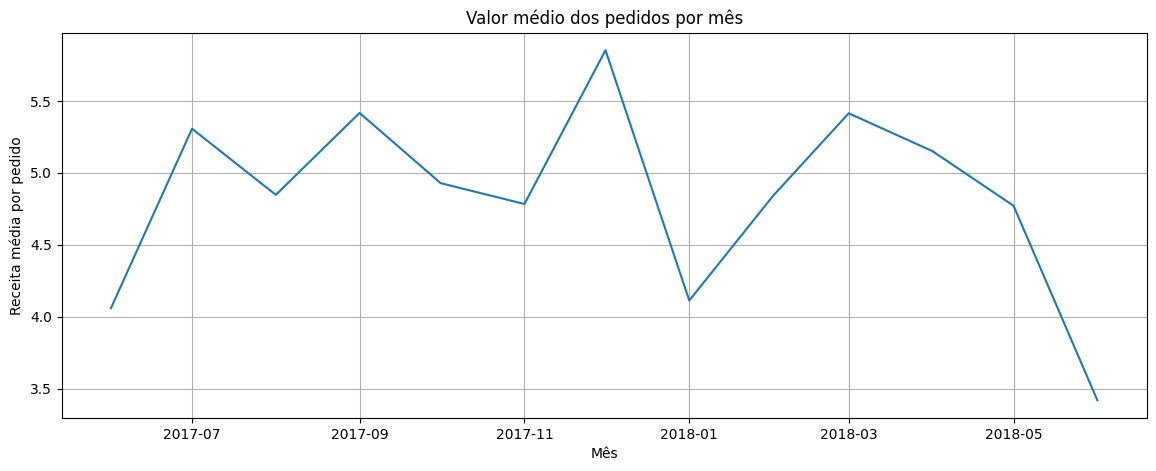

In [45]:
# Criando o gráfico do valor médio dos pedidos por mês

plt.figure(figsize=(14, 5))

plt.plot(
    average_order_value['order_month'],
    average_order_value['average_revenue']
)

plt.title('Valor médio dos pedidos por mês')
plt.xlabel('Mês')
plt.ylabel('Receita média por pedido')

plt.grid()

plt.show()

### Conclusão

Foi calculado o valor médio dos pedidos realizados pelos clientes.

O valor médio geral de uma compra foi de aproximadamente **5,00**. Ao observar o gráfico, percebe-se que o valor médio das compras apresentou pequenas variações entre os meses, permanecendo na maior parte do período entre **4 e 6**.

De forma geral, o valor médio dos pedidos manteve-se relativamente estável durante o período analisado, sem grandes oscilações.

### 2.2.4 Quanto dinheiro os clientes trazem para a empresa (LTV)?

#### Objetivo

Nesta etapa será calculado o LTV, que representa quanto dinheiro cada cliente traz para a empresa ao longo do tempo.

Para isso, os clientes serão agrupados em coortes de acordo com o mês da primeira compra.

In [46]:
# Criando o mês da primeira compra de cada usuário

first_order['first_order_month'] = (
    first_order['first_order_ts']
    .dt.to_period('M')
    .dt.to_timestamp()
)

display(first_order.head())

,uid,first_order_ts,first_order_month
0,313578113262317,2018-01-03 21:51:00,2018-01-01
1,1575281904278712,2017-06-03 10:13:00,2017-06-01
2,2429014661409475,2017-10-11 18:33:00,2017-10-01
3,2464366381792757,2018-01-28 15:54:00,2018-01-01
4,2551852515556206,2017-11-24 10:14:00,2017-11-01


In [47]:
# Adicionando o mês da primeira compra à tabela de pedidos

orders_ltv = orders.merge(
    first_order[['uid', 'first_order_month']],
    on='uid'
)

display(orders_ltv.head())

,buy_ts,revenue,uid,order_month,first_order_month
0,2017-06-01 00:10:00,17.00,10329302124590727494,2017-06-01,2017-06-01
1,2017-06-01 00:25:00,0.55,11627257723692907447,2017-06-01,2017-06-01
2,2017-06-01 00:27:00,0.37,17903680561304213844,2017-06-01,2017-06-01
3,2017-06-01 00:29:00,0.55,16109239769442553005,2017-06-01,2017-06-01
4,2017-06-01 07:58:00,0.37,14200605875248379450,2017-06-01,2017-06-01


In [48]:
# Calculando a quantidade de clientes em cada coorte

cohort_sizes_ltv = (
    first_order.groupby('first_order_month')
    .agg({'uid': 'nunique'})
    .reset_index()
)

cohort_sizes_ltv.columns = [
    'first_order_month',
    'n_buyers'
]

display(cohort_sizes_ltv)

,first_order_month,n_buyers
0,2017-06-01,2023
1,2017-07-01,1923
2,2017-08-01,1370
3,2017-09-01,2581
4,2017-10-01,4340
5,2017-11-01,4081
6,2017-12-01,4383
7,2018-01-01,3373
8,2018-02-01,3651
9,2018-03-01,3533


In [49]:
# Calculando a receita de cada coorte em cada mês

ltv_cohorts = (
    orders_ltv.groupby(
        ['first_order_month', 'order_month']
    )
    .agg({'revenue': 'sum'})
    .reset_index()
)

display(ltv_cohorts.head())

,first_order_month,order_month,revenue
0,2017-06-01,2017-06-01,9557.49
1,2017-06-01,2017-07-01,981.82
2,2017-06-01,2017-08-01,885.34
3,2017-06-01,2017-09-01,1931.30
4,2017-06-01,2017-10-01,2068.58


In [50]:
# Adicionando a quantidade inicial de compradores ao relatório

ltv_report = ltv_cohorts.merge(
    cohort_sizes_ltv,
    on='first_order_month'
)

display(ltv_report.head())

,first_order_month,order_month,revenue,n_buyers
0,2017-06-01,2017-06-01,9557.49,2023
1,2017-06-01,2017-07-01,981.82,2023
2,2017-06-01,2017-08-01,885.34,2023
3,2017-06-01,2017-09-01,1931.30,2023
4,2017-06-01,2017-10-01,2068.58,2023


In [51]:
# Calculando a idade da coorte em meses

ltv_report['cohort_age'] = (
    (
        ltv_report['order_month'].dt.year
        - ltv_report['first_order_month'].dt.year
    ) * 12
    + (
        ltv_report['order_month'].dt.month
        - ltv_report['first_order_month'].dt.month
    )
)

display(ltv_report.head())

,first_order_month,order_month,revenue,n_buyers,cohort_age
0,2017-06-01,2017-06-01,9557.49,2023,0
1,2017-06-01,2017-07-01,981.82,2023,1
2,2017-06-01,2017-08-01,885.34,2023,2
3,2017-06-01,2017-09-01,1931.30,2023,3
4,2017-06-01,2017-10-01,2068.58,2023,4


In [52]:
# Calculando o LTV mensal de cada coorte

ltv_report['ltv'] = (
    ltv_report['revenue']
    / ltv_report['n_buyers']
)

display(ltv_report.head())

,first_order_month,order_month,revenue,n_buyers,cohort_age,ltv
0,2017-06-01,2017-06-01,9557.49,2023,0,4.724414
1,2017-06-01,2017-07-01,981.82,2023,1,0.485329
2,2017-06-01,2017-08-01,885.34,2023,2,0.437637
3,2017-06-01,2017-09-01,1931.30,2023,3,0.954671
4,2017-06-01,2017-10-01,2068.58,2023,4,1.022531


In [53]:
# Criando a tabela dinâmica com o LTV mensal

ltv_pivot = ltv_report.pivot_table(
    index='first_order_month',
    columns='cohort_age',
    values='ltv',
    aggfunc='mean'
)

display(ltv_pivot.round(2))

cohort_age,0,1,2,3,4,5,6,7,8,9,10,11
first_order_month,,,,,,,,,,,,
2017-06-01,4.72,0.49,0.44,0.95,1.02,0.74,0.95,0.58,0.55,0.61,0.57,0.26
2017-07-01,6.01,0.34,0.62,0.36,0.18,0.16,0.12,0.14,0.16,0.15,0.16,NaN
2017-08-01,5.28,0.47,0.46,0.39,0.49,0.28,0.21,0.41,0.29,0.19,NaN,NaN
2017-09-01,5.64,1.12,0.52,3.98,0.40,0.65,0.70,0.24,0.18,NaN,NaN,NaN
2017-10-01,5.00,0.54,0.19,0.16,0.15,0.12,0.08,0.12,NaN,NaN,NaN,NaN
2017-11-01,5.15,0.40,0.20,0.32,0.15,0.05,0.11,NaN,NaN,NaN,NaN,NaN
2017-12-01,4.74,0.26,0.93,1.07,0.31,0.34,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01,4.14,0.29,0.30,0.14,0.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-01,4.16,0.28,0.08,0.07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [54]:
# Calculando o LTV acumulado ao longo dos meses

ltv_cumulative = ltv_pivot.cumsum(axis=1)

display(ltv_cumulative.round(2))

cohort_age,0,1,2,3,4,5,6,7,8,9,10,11
first_order_month,,,,,,,,,,,,
2017-06-01,4.72,5.21,5.65,6.60,7.62,8.36,9.31,9.89,10.45,11.05,11.62,11.88
2017-07-01,6.01,6.35,6.97,7.33,7.50,7.66,7.78,7.92,8.08,8.23,8.39,NaN
2017-08-01,5.28,5.75,6.21,6.60,7.09,7.38,7.59,7.99,8.28,8.47,NaN,NaN
2017-09-01,5.64,6.76,7.28,11.26,11.66,12.31,13.01,13.25,13.44,NaN,NaN,NaN
2017-10-01,5.00,5.54,5.73,5.89,6.04,6.16,6.24,6.36,NaN,NaN,NaN,NaN
2017-11-01,5.15,5.55,5.75,6.08,6.23,6.28,6.40,NaN,NaN,NaN,NaN,NaN
2017-12-01,4.74,5.00,5.92,6.99,7.30,7.64,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01,4.14,4.43,4.73,4.88,4.94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-01,4.16,4.44,4.51,4.59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


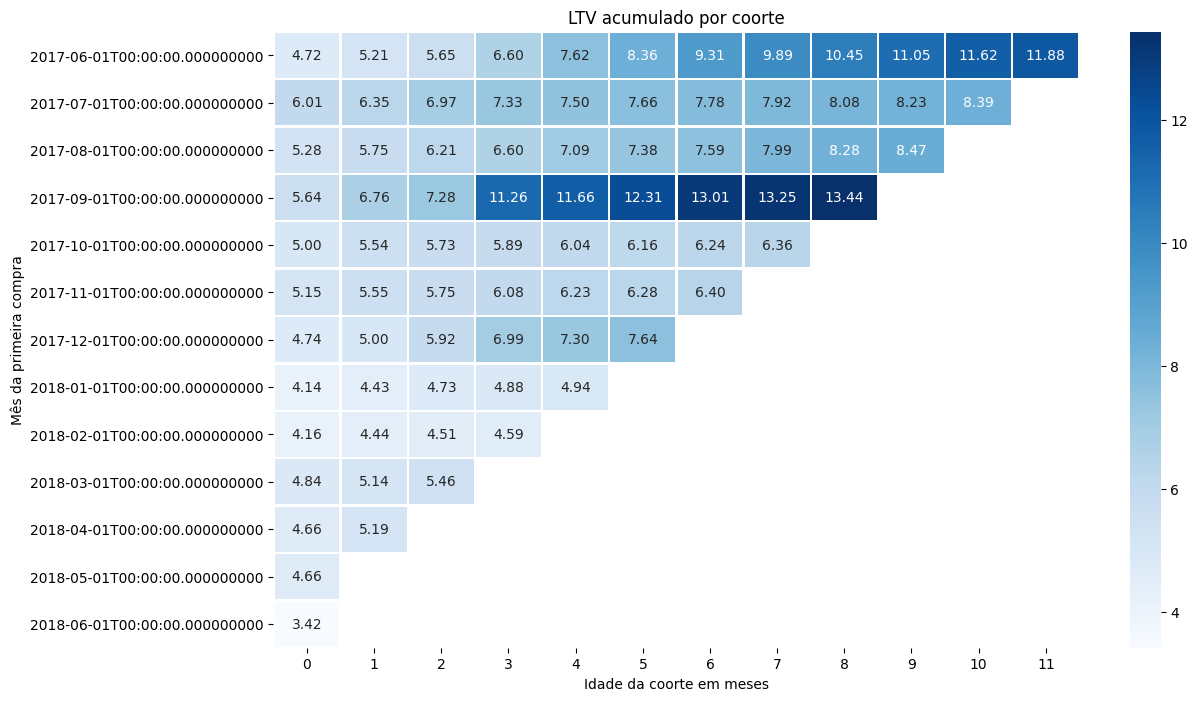

In [55]:
# Criando o mapa de calor do LTV acumulado

plt.figure(figsize=(13, 8))

sns.heatmap(
    ltv_cumulative,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    linewidths=1,
    linecolor='white'
)

plt.title('LTV acumulado por coorte')
plt.xlabel('Idade da coorte em meses')
plt.ylabel('Mês da primeira compra')

plt.show()

In [56]:
# Calculando o LTV médio das coortes em cada mês de vida

mean_ltv = ltv_cumulative.mean(axis=0)

display(mean_ltv.round(2))

cohort_age
0      4.80
1      5.40
2      5.82
3      6.69
4      7.30
5      7.97
6      8.39
7      9.08
8     10.06
9      9.25
10    10.00
11    11.88
dtype: float64

### Conclusão

Foi calculado o LTV (Lifetime Value) dos clientes utilizando coortes baseadas no mês da primeira compra.

O mapa de calor mostra que o LTV aumenta conforme a idade da coorte, indicando que os clientes continuam gerando receita ao longo dos meses após a primeira compra.

Observa-se também que algumas coortes apresentam um LTV acumulado maior que outras, mas, de forma geral, todas apresentam crescimento ao longo do tempo, mostrando que os clientes continuam realizando novas compras.

## 2.3 Marketing

Nesta seção serão analisadas as métricas relacionadas aos investimentos em marketing.

Serão respondidas as seguintes perguntas:

- Quanto dinheiro foi gasto? (No total, por origem e ao longo do tempo)
- Quanto custou a aquisição de clientes para cada origem?
- Os investimentos valeram a pena? (ROI)

### 2.3.1 Quanto dinheiro foi gasto? (No total, por origem e ao longo do tempo)

#### Objetivo

Nesta etapa serão analisadas as despesas com marketing.

Serão calculados o gasto total, o gasto por origem de anúncio e a evolução dessas despesas ao longo do tempo.

In [57]:
# Calculando o gasto total com marketing

total_cost = costs['costs'].sum()

print(
    'Total gasto em marketing:',
    round(total_cost, 2)
)

Total gasto em marketing: 329131.62


In [58]:
# Calculando o gasto por origem

costs_by_source = (
    costs.groupby('source_id')
    .agg({'costs':'sum'})
    .reset_index()
)

costs_by_source.columns = [
    'source_id',
    'total_cost'
]

display(costs_by_source)

,source_id,total_cost
0,1,20833.27
1,2,42806.04
2,3,141321.63
3,4,61073.60
4,5,51757.10
5,9,5517.49
6,10,5822.49


In [59]:
# Criando a coluna do mês

costs['cost_month'] = (
    costs['dt']
    .dt.to_period('M')
    .dt.to_timestamp()
)

display(costs.head())

,source_id,dt,costs,cost_month
0,1,2017-06-01,75.20,2017-06-01
1,1,2017-06-02,62.25,2017-06-01
2,1,2017-06-03,36.53,2017-06-01
3,1,2017-06-04,55.00,2017-06-01
4,1,2017-06-05,57.08,2017-06-01


In [60]:
# Calculando os gastos por mês

monthly_costs = (
    costs.groupby('cost_month')
    .agg({'costs':'sum'})
    .reset_index()
)

monthly_costs.columns = [
    'cost_month',
    'total_cost'
]

display(monthly_costs)

,cost_month,total_cost
0,2017-06-01,18015.00
1,2017-07-01,18240.59
2,2017-08-01,14790.54
3,2017-09-01,24368.91
4,2017-10-01,36322.88
5,2017-11-01,37907.88
6,2017-12-01,38315.35
7,2018-01-01,33518.52
8,2018-02-01,32723.03
9,2018-03-01,30415.27


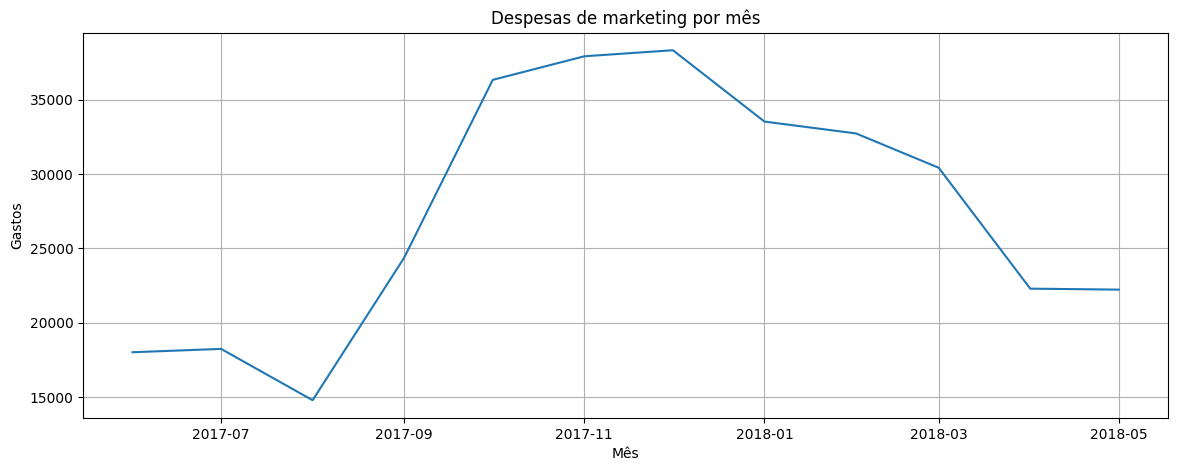

In [61]:
plt.figure(figsize=(14,5))

plt.plot(
    monthly_costs['cost_month'],
    monthly_costs['total_cost']
)

plt.title('Despesas de marketing por mês')
plt.xlabel('Mês')
plt.ylabel('Gastos')

plt.grid()

plt.show()

In [62]:
print(
    'Gasto médio mensal:',
    round(monthly_costs['total_cost'].mean(),2)
)

Gasto médio mensal: 27427.63


### Conclusão

Durante o período analisado, a empresa investiu um total de **329.131,62** em marketing, com um gasto médio mensal de aproximadamente **27.427,63**.

Ao analisar os investimentos por origem de anúncios, observa-se que a **origem 3** recebeu a maior parte do orçamento, seguida pelas origens **4** e **5**, indicando que essas fontes eram consideradas prioritárias na estratégia de aquisição de clientes.

O gráfico mostra que as despesas aumentaram gradualmente entre setembro e dezembro de 2017, atingindo seu pico nesse período. A partir de janeiro de 2018, os investimentos começaram a diminuir de forma consistente, sugerindo uma redução do orçamento ou uma otimização das campanhas de marketing.

Essas informações servirão de base para comparar os custos de aquisição de clientes (CAC) e avaliar se os investimentos realizados geraram retorno suficiente para a empresa.

### 2.3.2 Quanto custou a aquisição de clientes para cada origem?

#### Objetivo

Nesta etapa será calculado o CAC (Customer Acquisition Cost) de cada origem de anúncio.

Essa análise permite identificar quanto a empresa gastou, em média, para adquirir um cliente em cada canal de marketing e comparar a eficiência das diferentes origens.

In [63]:
# Encontrando a primeira visita de cada usuário

first_visits = (
    visits.sort_values('start_ts')
    .groupby('uid')
    .first()
    .reset_index()
)

display(first_visits.head())

,uid,device,end_ts,source_id,start_ts,session_date,session_week,session_month,session_duration_sec,first_session_month,cohort_age
0,11863502262781,touch,2018-03-01 17:33:00,3,2018-03-01 17:27:00,2018-03-01,2018-02-26,2018-03-01,360,2018-03-01,0
1,49537067089222,touch,2018-02-06 15:57:00,2,2018-02-06 15:55:00,2018-02-06,2018-02-05,2018-02-01,120,2018-02-01,0
2,297729379853735,desktop,2017-06-07 18:48:00,3,2017-06-07 18:47:00,2017-06-07,2017-06-05,2017-06-01,60,2017-06-01,0
3,313578113262317,desktop,2017-09-18 23:07:00,2,2017-09-18 22:49:00,2017-09-18,2017-09-18,2017-09-01,1080,2017-09-01,0
4,325320750514679,desktop,2017-09-30 14:38:00,5,2017-09-30 14:29:00,2017-09-30,2017-09-25,2017-09-01,540,2017-09-01,0


In [64]:
# Relacionando a primeira visita com os usuários que compraram

buyers = (
    first_visits[['uid', 'source_id']]
    .merge(
        first_order[['uid']],
        on='uid'
    )
)

display(buyers.head())

,uid,source_id
0,313578113262317,2
1,1575281904278712,10
2,2429014661409475,3
3,2464366381792757,5
4,2551852515556206,5


In [65]:
# Calculando a quantidade de compradores por origem

buyers_by_source = (
    buyers.groupby('source_id')
    .agg({'uid': 'nunique'})
    .reset_index()
)

buyers_by_source.columns = [
    'source_id',
    'n_buyers'
]

display(buyers_by_source)

,source_id,n_buyers
0,1,2899
1,2,3506
2,3,10473
3,4,10296
4,5,6931
5,7,1
6,9,1088
7,10,1329


In [66]:
# Unindo compradores e custos

cac = costs_by_source.merge(
    buyers_by_source,
    on='source_id'
)

display(cac)

,source_id,total_cost,n_buyers
0,1,20833.27,2899
1,2,42806.04,3506
2,3,141321.63,10473
3,4,61073.60,10296
4,5,51757.10,6931
5,9,5517.49,1088
6,10,5822.49,1329


In [67]:
# Calculando o CAC por comprador

cac['cac'] = (
    cac['total_cost']
    / cac['n_buyers']
)

display(cac.round(2))

,source_id,total_cost,n_buyers,cac
0,1,20833.27,2899,7.19
1,2,42806.04,3506,12.21
2,3,141321.63,10473,13.49
3,4,61073.60,10296,5.93
4,5,51757.10,6931,7.47
5,9,5517.49,1088,5.07
6,10,5822.49,1329,4.38


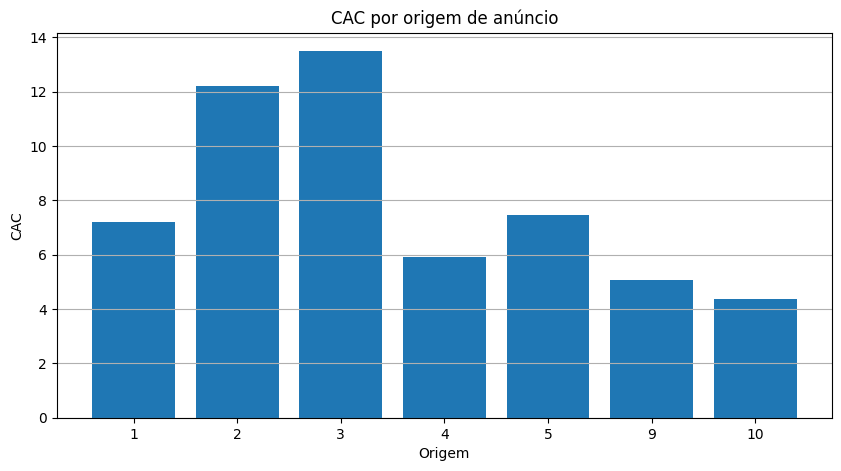

In [68]:
plt.figure(figsize=(10,5))

plt.bar(
    cac['source_id'].astype(str),
    cac['cac']
)

plt.title('CAC por origem de anúncio')
plt.xlabel('Origem')
plt.ylabel('CAC')

plt.grid(axis='y')

plt.show()

### Conclusão

O CAC (Custo de Aquisição de Clientes) foi calculado para cada origem de anúncio dividindo o investimento total pelo número de usuários que realmente realizaram uma compra.

Os resultados mostram diferenças entre as origens. As origens 3 e 2 apresentaram os maiores custos de aquisição, com CAC de aproximadamente 13,49 e 12,21, respectivamente.

Já as origens 10, 9 e 4 apresentaram os menores custos, com CAC de aproximadamente 4,38, 5,07 e 5,93, respectivamente. A origem 1 apresentou CAC de 7,19 e a origem 5 de 7,47.

Assim, algumas origens conseguem adquirir compradores com um custo menor do que outras. Na próxima etapa, esses valores serão comparados com o retorno gerado pelos compradores para avaliar se os investimentos em marketing valeram a pena.

### 2.3.3 Os investimentos valeram a pena? (ROI)

#### Objetivo

Nesta etapa será calculado o retorno sobre o investimento em marketing (ROI), comparando a receita gerada pelos clientes com os custos de aquisição.

Essa análise permite identificar quais origens de anúncio proporcionaram o melhor retorno financeiro e quais campanhas apresentaram maior eficiência para a empresa.

In [69]:
# Calculando o LTV final de cada coorte

ltv_final = (
    ltv_report.groupby('first_order_month')
    .agg({'ltv':'sum'})
    .reset_index()
)

display(ltv_final)

,first_order_month,ltv
0,2017-06-01,11.879234
1,2017-07-01,8.386854
2,2017-08-01,8.471723
3,2017-09-01,13.435227
4,2017-10-01,6.360242
5,2017-11-01,6.395244
6,2017-12-01,7.639913
7,2018-01-01,4.940151
8,2018-02-01,4.587921
9,2018-03-01,5.455253


In [70]:
# Relacionando compradores com a origem da primeira visita

buyers_sources = (
    first_visits[['uid','source_id']]
    .merge(
        first_order[['uid','first_order_month']],
        on='uid'
    )
)

display(buyers_sources.head())

,uid,source_id,first_order_month
0,313578113262317,2,2018-01-01
1,1575281904278712,10,2017-06-01
2,2429014661409475,3,2017-10-01
3,2464366381792757,5,2018-01-01
4,2551852515556206,5,2017-11-01


In [71]:
# LTV médio por origem

ltv_source = (
    buyers_sources
    .merge(
        ltv_final,
        on='first_order_month'
    )
    .groupby('source_id')
    .agg({'ltv':'mean'})
    .reset_index()
)

display(ltv_source.round(2))

,source_id,ltv
0,1,7.03
1,2,6.89
2,3,6.95
3,4,6.69
4,5,7.08
5,7,8.47
6,9,7.12
7,10,6.78


In [72]:
# Unindo LTV e CAC

roi = ltv_source.merge(
    cac[['source_id','cac']],
    on='source_id'
)

display(roi.round(2))

,source_id,ltv,cac
0,1,7.03,7.19
1,2,6.89,12.21
2,3,6.95,13.49
3,4,6.69,5.93
4,5,7.08,7.47
5,9,7.12,5.07
6,10,6.78,4.38


In [73]:
# Calculando o ROMI

roi['romi'] = (
    roi['ltv']
    / roi['cac']
)

display(roi.round(2))

,source_id,ltv,cac,romi
0,1,7.03,7.19,0.98
1,2,6.89,12.21,0.56
2,3,6.95,13.49,0.51
3,4,6.69,5.93,1.13
4,5,7.08,7.47,0.95
5,9,7.12,5.07,1.40
6,10,6.78,4.38,1.55


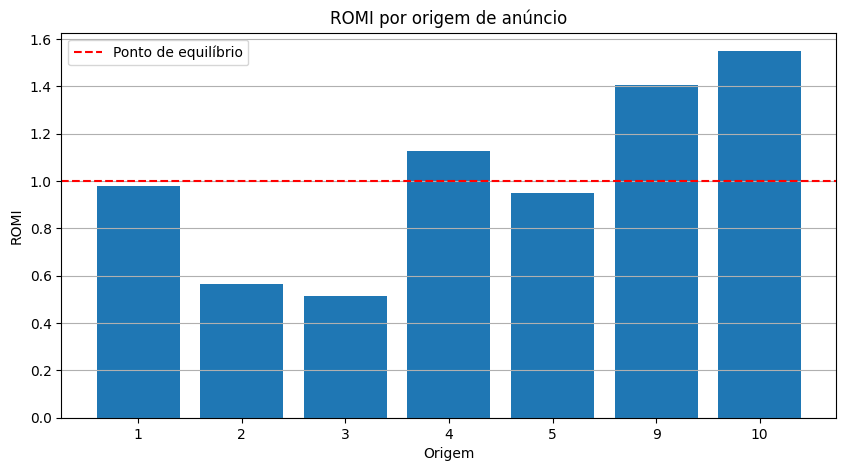

In [74]:
plt.figure(figsize=(10,5))

plt.bar(
    roi['source_id'].astype(str),
    roi['romi']
)

plt.axhline(
    y=1,
    color='red',
    linestyle='--',
    label='Ponto de equilíbrio'
)

plt.title('ROMI por origem de anúncio')
plt.xlabel('Origem')
plt.ylabel('ROMI')

plt.legend()

plt.grid(axis='y')

plt.show()

### Conclusão

O ROMI foi calculado comparando o LTV dos compradores com o CAC por comprador de cada origem de anúncio.

Os resultados mostram que as origens 4, 9 e 10 apresentaram ROMI acima de 1, indicando um retorno superior ao custo de aquisição. Entre elas, a origem 10 apresentou o melhor resultado, seguida pelas origens 9 e 4.

Por outro lado, as origens 1, 2, 3 e 5 apresentaram ROMI abaixo de 1. As origens 2 e 3 tiveram os menores resultados.

Portanto, as origens 10, 9 e 4 apresentaram os melhores resultados de marketing no período analisado.

## Passo 3 — Conclusão Final

Durante este projeto foi possível analisar como os usuários utilizam a plataforma, o comportamento de compra e o desempenho dos investimentos em marketing.

Na análise do Produto, observou-se que a quantidade de usuários e de sessões variou ao longo dos meses. O tempo médio das sessões permaneceu relativamente estável e parte dos usuários retornou para utilizar a plataforma novamente.

Na análise de Vendas, foi possível observar o comportamento dos clientes após a primeira compra e acompanhar a receita gerada ao longo do tempo.

Na análise de Marketing, o CAC foi calculado considerando apenas os usuários que realmente realizaram uma compra. Os resultados mostraram diferenças entre as origens de anúncio, sendo que algumas conseguiram adquirir compradores com um custo menor do que outras.

Ao comparar o LTV com o CAC, as origens 4, 9 e 10 apresentaram ROMI acima de 1, indicando retorno superior ao custo de aquisição. Entre elas, a origem 10 apresentou o maior ROMI, seguida pelas origens 9 e 4. Já as origens 1, 2, 3 e 5 apresentaram ROMI abaixo de 1 no período analisado.

Com base nos resultados, as origens 10, 9 e 4 apresentaram o melhor desempenho de marketing. Portanto, a empresa pode considerar essas origens como as mais eficientes no período analisado e avaliar com mais atenção as origens que apresentaram ROMI abaixo de 1.